*  DSC640-T302 Data Presentation & Visualization (2267-1)
*  Weeks 9 & 10 Assignment - TSA Complaints
*  David Jorgensen

# Weeks 9 & 10 Assignment - TSA Complaints

Datasets:
- `data/complaints-by-subcategory.csv`
- `data/iata-icao.csv`
- `data/complaints-by-category.csv`
- `data/complaints-by-airport.csv`

Dataset Sources:
- Provides the specific complaint information across 3 files: [GitHub tsa-complaint-counts](https://github.com/data-liberation-project/tsa-complaint-counts/tree/main)
- Provides the airport location & look-up codes, which will be needed to narrow in on what airport had specific TSA complaints: [IATA/ICAO](https://github.com/ip2location/ip2location-iata-icao)

Supplemental data (added so complaints can be expressed as a *rate*, not a raw count):
- `data/faa-cy2024-enplanements.xlsx` - FAA CY2024 Commercial Service Enplanements (contains both CY2023 and CY2024 boardings, FAA hub class, and state): [FAA Passenger Boarding Data](https://www.faa.gov/airports/planning_capacity/passenger_allcargo_stats/passenger)
- `data/us-states.geojson` - public-domain US state boundary polygons used only to draw the choropleth

---
# The Flood and the Floor
### Two TSA complaint problems wearing the same uniform (2015-2023)

| | |
|---|---|
| **Audience** | **TSA senior leadership** - the Administrator's senior staff, specifically the Executive Assistant Administrators for **Security Operations** and for **Enrollment Services & Vetting Programs**, plus the **Contact Center** chief. This is an internal, data-fluent, executive audience that already lives in this data, so the briefing keeps TSA vocabulary (PreCheck, TSO, hub class, enplanements) undefined, skips the data dictionary, and leads with the decision instead of the table. |
| **Purpose / Call to Action** | **Approve two funded actions for FY2027.** (1) **Re-code the expedited-screening intake taxonomy and stand up self-service PreCheck application-status lookup** - 78% of 2023 complaints are PreCheck-program traffic and the single largest bucket is *unlabeled*, so three quarters of the mailbag is currently unmanageable. (2) **Fund a 90-day "Checkpoint Ten" intervention** at the ten highest-rate large/medium hubs, with a target of reaching the peer median by the end of CY2027. The gap is not explained by airport size, and closing it at those ten airports alone removes ~2,600 complaints a year. |
| **Medium** | A **nine-slide executive briefing deck** (`deck/tsa_checkpoint_briefing.html`, one self-contained file that prints straight to PDF). Executives get a 15-minute slot: one chart per slide, a takeaway sentence as the headline, and a hard ask on the closing slide. The notebook below is the analyst appendix that produces every slide. |

**The story in three sentences.** TSA's complaint mailbag looks like it exploded - it more than doubled between 2021 and 2023 and sits 53% above 2019 - but almost all of that growth is one category, the expedited-screening (PreCheck) program, which is a national enrollment problem and not something a checkpoint can fix. Strip PreCheck out and the real checkpoint signal is small, stable, and *very* unevenly distributed: among 57 comparable large and medium hubs, the checkpoint complaint rate ranges 3.7x from CLT to CMH, and airport size explains none of it. That spread is the floor under the flood, and it is the part leadership can actually manage.

In [1]:
# --- Setup & briefing visual identity (applied to every figure) -------------
# The identity is the client's own. Every color, both typefaces and the flat,
# square, hairline-ruled structure below are lifted from the TSA.gov design
# system (the tsa_uswds theme, built on the U.S. Web Design System), so the
# deck lands on the Administrator's desk looking like a TSA document.

# Libraries
import base64, glob, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import matplotlib.patheffects as pe
import geopandas as gpd
from matplotlib import font_manager as fm
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Patch
from matplotlib.ticker import FuncFormatter
warnings.filterwarnings("ignore")

# TSA.gov tokens. #005288 is the agency primary (nav bar, buttons, links, H1,
# footer); #c41230 is the agency accent (section headings, alert strips). The
# greys, the warm orange and the blue tints are USWDS base / accent tokens the
# theme already ships, so nothing here is invented.
TSA_BLUE, BLUE_DK, BLUE_MD = "#005288", "#162e51", "#0071b8"
BLUE_LT, BLUE_PALE, BLUE_MIST = "#28a0cb", "#97d4ea", "#d9e8f6"
TSA_RED, ORANGE, ORANGE_LT = "#c41230", "#c05600", "#f4e3db"
INK, BASE, RULE, SHADE = "#1b1b1b", "#565c65", "#dfe1e2", "#edeeee"

# The story encoding is unchanged, only restated in the client's palette:
# ORANGE  = the PreCheck *program* problem
# TSA_BLUE = the *checkpoint* problem leadership can manage
# TSA_RED  = call-outs and the ask
# BASE/RULE/SHADE = context, gridlines, suppressed data

# One sequential ramp, interpolated through the theme's own blue tints, so
# saturation always means "more checkpoint complaints" and never introduces a
# second hue. Luminance falls monotonically from end to end.
TSA_SEQ = LinearSegmentedColormap.from_list(
    "tsa_seq", ["#eff5fa", BLUE_MIST, BLUE_PALE, BLUE_LT, BLUE_MD, TSA_BLUE, BLUE_DK])

def ramp_text(v, vmax):
    """Label color that stays legible at both ends of TSA_SEQ (>= 4.4:1)."""
    return "white" if vmax and v / vmax > 0.62 else INK

# Type: TSA.gov sets headings in Merriweather and everything else in Source Sans
# Pro. Both faces live in fonts/ so the figures render identically off-network.
for _ttf in sorted(glob.glob("fonts/*.ttf")):
    fm.fontManager.addfont(_ttf)
SERIF, SANS = "Merriweather", "Source Sans 3"

# Set global style parameters
plt.rcParams.update({
    "figure.figsize": (11, 5.5), "figure.dpi": 110,
    "savefig.dpi": 150, "savefig.bbox": "tight", "savefig.facecolor": "white",
    "font.family": SANS, "font.size": 11,
    "axes.titlesize": 15, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.titlecolor": BLUE_DK, "axes.titlepad": 16,
    "axes.labelcolor": INK, "axes.labelsize": 10.5,
    "axes.edgecolor": RULE, "axes.linewidth": 1.2,
    "axes.facecolor": "white", "axes.grid": True,
    "axes.axisbelow": True, "axes.spines.top": False, "axes.spines.right": False,
    "grid.color": RULE, "grid.linewidth": 0.8,
    "xtick.color": BASE, "ytick.color": BASE,
    "xtick.labelcolor": INK, "ytick.labelcolor": INK,
    "text.color": INK, "legend.frameon": False, "legend.fontsize": 9.5,
    "figure.facecolor": "white",
})

def tsa_title(ax, text, rule=True):
    """TSA.gov heading treatment: Merriweather bold, flush left, seated on the
    thin agency-blue rule the theme puts under a section heading."""
    ax.set_title(text, fontfamily=SERIF)
    if rule:
        ax.plot([0, 1], [1.012, 1.012], transform=ax.transAxes, color=TSA_BLUE,
                lw=2.6, clip_on=False, zorder=5, solid_capstyle="butt")

thousands = FuncFormatter(lambda v, p: f"{v:,.0f}")

DATA, FIGS = "data/", "figures/"
PRE = "Expedited Passenger Screening Program"     # the runaway category


In [2]:
# --- Load the four provided files plus the two supplemental ones -----------
apt  = pd.read_csv(DATA + "complaints-by-airport.csv")
cat  = pd.read_csv(DATA + "complaints-by-category.csv")
sub  = pd.read_csv(DATA + "complaints-by-subcategory.csv")
iata = pd.read_csv(DATA + "iata-icao.csv")
faa  = pd.read_excel(DATA + "faa-cy2024-enplanements.xlsx")

for d in (apt, cat, sub):
    d["month"] = pd.PeriodIndex(d["year_month"], freq="M").to_timestamp()
    d["yr"] = d["year_month"].str[:4].astype(int)

print(f"airport rows {len(apt):,} | category rows {len(cat):,} | subcategory rows {len(sub):,}")
print(f"IATA lookup {len(iata):,} airports | FAA enplanement rows {len(faa):,}")
print(f"complaint window {apt.year_month.min()} .. {apt.year_month.max()}")

airport rows 41,721 | category rows 241,588 | subcategory rows 504,512
IATA lookup 8,937 airports | FAA enplanement rows 520
complaint window 2015-01 .. 2024-01


In [3]:
# --- Audit 1: do the seven source PDFs overlap or disagree? ----------------
# The complaint files are stitched from seven separate TSA PDF releases. Before
# summing anything we confirm each (airport, month) is reported exactly once, so
# no complaint is double counted and no de-duplication rule has to be invented.
pairs = apt.groupby(["airport", "year_month"])["count"].agg(["size", "nunique"])
print("report windows:")
print(apt.groupby("pdf_report_date").year_month.agg(["min", "max"]).to_string())
print(f"\n(airport, month) pairs reported more than once : {(pairs['size'] > 1).sum()}")
print(f"(airport, month) pairs with disagreeing counts   : {(pairs['nunique'] > 1).sum()}")
print(f"grand totals agree across files: "
      f"{apt['count'].sum() == cat['count'].sum() == sub['count'].sum()} "
      f"({apt['count'].sum():,} complaints)")

report windows:
                     min      max
pdf_report_date                  
2019-02          2015-01  2015-12
2019-12          2016-01  2017-12
2021-06          2018-01  2018-12
2022-05          2019-01  2019-12
2023-05          2020-01  2021-08
2023-08          2021-09  2021-09
2024-02          2021-10  2024-01

(airport, month) pairs reported more than once : 0
(airport, month) pairs with disagreeing counts   : 0
grand totals agree across files: True (1,021,281 complaints)


In [4]:
# --- Audit 2: the unattributed bucket (disclosed, never silently dropped) --
# 43% of all complaints carry a BLANK airport code. They are not a national
# subtotal (some months they are smaller than the attributed sum), they are a
# separate "no airport recorded" bucket - and they are overwhelmingly PreCheck,
# which is exactly the point of the story: that traffic has no checkpoint.
una = cat[cat.airport.isna()]
att = cat[cat.airport.notna()]
print(f"unattributed complaints : {una['count'].sum():,} "
      f"({una['count'].sum() / cat['count'].sum():.1%} of all complaints)")
print(f"...of which PreCheck    : {una.loc[una.clean_cat == PRE, 'count'].sum():,} "
      f"({una.loc[una.clean_cat == PRE, 'count'].sum() / una['count'].sum():.1%})")
print("\ntop categories in the unattributed bucket:")
print(una.groupby("clean_cat")["count"].sum().nlargest(5).to_string())
print("\nEvery airport-level chart below uses ONLY the 57% that carries an airport "
      "code.\nEvery national trend chart uses 100% of the rows.")

unattributed complaints : 437,786 (42.9% of all complaints)
...of which PreCheck    : 353,570 (80.8%)

top categories in the unattributed bucket:
clean_cat
Expedited Passenger Screening Program    353570
Mishandling of Passenger Property         15122
Airline                                   10668
No Jurisdiction                            9384
Hazardous Materials Safety                 9368

Every airport-level chart below uses ONLY the 57% that carries an airport code.
Every national trend chart uses 100% of the rows.


In [5]:
# --- Audit 3: reconciling the two airport lookups -------------------------
# iata-icao.csv and the FAA file both name a state for each airport. They disagree
# on 7 airports, and the FAA (the operator of record) is authoritative, so state
# assignment comes from FAA and the IATA file supplies airport names and coordinates.
STATES = {"AL":"Alabama","AK":"Alaska","AZ":"Arizona","AR":"Arkansas","CA":"California",
    "CO":"Colorado","CT":"Connecticut","DE":"Delaware","FL":"Florida","GA":"Georgia",
    "HI":"Hawaii","ID":"Idaho","IL":"Illinois","IN":"Indiana","IA":"Iowa","KS":"Kansas",
    "KY":"Kentucky","LA":"Louisiana","ME":"Maine","MD":"Maryland","MA":"Massachusetts",
    "MI":"Michigan","MN":"Minnesota","MS":"Mississippi","MO":"Missouri","MT":"Montana",
    "NE":"Nebraska","NV":"Nevada","NH":"New Hampshire","NJ":"New Jersey","NM":"New Mexico",
    "NY":"New York","NC":"North Carolina","ND":"North Dakota","OH":"Ohio","OK":"Oklahoma",
    "OR":"Oregon","PA":"Pennsylvania","RI":"Rhode Island","SC":"South Carolina",
    "SD":"South Dakota","TN":"Tennessee","TX":"Texas","UT":"Utah","VT":"Vermont",
    "VA":"Virginia","WA":"Washington","WV":"West Virginia","WI":"Wisconsin",
    "WY":"Wyoming","DC":"District of Columbia","PR":"Puerto Rico"}

faa = faa.rename(columns={"Locid": "iata", "ST": "st", "Hub": "hub",
                          "CY 23 Enplanements": "enp23", "Airport Name": "faa_name"})
faa = faa[faa.iata.astype(str).str.fullmatch(r"[A-Z0-9]{3}")]      # strips footnote rows
faa = faa[["iata", "st", "hub", "faa_name", "enp23"]].dropna(subset=["enp23"])
faa["state"] = faa.st.map(STATES)

look = (iata[iata.country_code == "US"]
        [["iata", "airport", "region_name", "latitude", "longitude"]]
        .rename(columns={"airport": "airport_name", "region_name": "iata_state"}))

chk = faa.merge(look, on="iata", how="left")
bad = chk[chk.iata_state.notna() & (chk.iata_state != chk.state)]
print(f"state disagreements between the IATA lookup and FAA: {len(bad)}")
print(bad[["iata", "airport_name", "state", "iata_state", "enp23"]]
      .sort_values("enp23", ascending=False).to_string(index=False))

state disagreements between the IATA lookup and FAA: 7
iata                     airport_name       state    iata_state     enp23
 OMA                  Eppley Airfield    Nebraska          Iowa 2464418.0
 BQN         Rafael Hernandez Airport Puerto Rico Massachusetts  432822.0
 BVU                   Beluga Airport      Nevada        Alaska   49841.0
 VQS Antonio Rivera Rodriguez Airport Puerto Rico Massachusetts   28961.0
 RVR    Green River Municipal Airport Puerto Rico          Utah   19786.0
 CPX  Benjamin Rivera Noriega Airport Puerto Rico Massachusetts   18922.0
 MAZ  Eugenio Maria de Hostos Airport Puerto Rico Massachusetts    8224.0


In [6]:
# --- Build the 2023 airport x category rate table -------------------------
# 2023 is the last complete calendar year in the complaint data (it ends 2024-01),
# and CY2023 boardings are the matching denominator, so the rate is like-for-like.
apt_c, cat_c, sub_c = apt[apt.yr <= 2023], cat[cat.yr <= 2023], sub[sub.yr <= 2023]

p23 = (cat_c[(cat_c.yr == 2023) & cat_c.airport.notna()]
       .pivot_table(index="airport", columns="clean_cat", values="count", aggfunc="sum")
       .fillna(0))
catcols = list(p23.columns)

rates = (faa.set_index("iata")[["state", "hub", "enp23"]]
         .join(p23, how="inner")
         .join(look.set_index("iata")[["airport_name", "latitude", "longitude"]], how="left"))
rates = rates[rates.enp23 > 0]
rates["airport_name"] = rates.airport_name.fillna(
    faa.set_index("iata").faa_name).fillna(rates.index.to_series())
rates["total"]      = rates[catcols].sum(axis=1)
rates["checkpoint"] = rates["total"] - rates[PRE]          # everything but the program
rates["cp_rate"]    = rates.checkpoint / (rates.enp23 / 1e6)
rates["all_rate"]   = rates.total / (rates.enp23 / 1e6)

NAT_CP = rates.checkpoint.sum() / (rates.enp23 / 1e6).sum()
peers  = rates[rates.enp23 >= 3e6].copy()                  # >=3M CY23 boardings
MED    = peers.cp_rate.median()
peers["excess"] = ((peers.cp_rate - MED) * peers.enp23 / 1e6).clip(lower=0)
worst10 = peers.nlargest(10, "cp_rate")

print(f"airports matched to boardings : {len(rates)}")
print(f"comparable peer set (>=3M)    : {len(peers)}  |  peer median rate {MED:.1f} / million")
print(f"spread across peers           : {peers.cp_rate.max() / peers.cp_rate.min():.2f}x "
      f"({peers.cp_rate.idxmax()} {peers.cp_rate.max():.0f} vs "
      f"{peers.cp_rate.idxmin()} {peers.cp_rate.min():.0f})")
print(f"closable gap, all 28 above median : {peers.excess.sum():,.0f} complaints / yr")
print(f"closable gap, worst 10 only       : {worst10.excess.sum():,.0f} complaints / yr "
      f"({worst10.excess.sum() / peers.excess.sum():.0%} of the total)")

airports matched to boardings : 403
comparable peer set (>=3M)    : 57  |  peer median rate 35.7 / million
spread across peers           : 3.65x (CMH 63 vs CLT 17)
closable gap, all 28 above median : 3,381 complaints / yr
closable gap, worst 10 only       : 2,631 complaints / yr (78% of the total)


## Visual 1 | Line chart: the flood, and what it actually is
Splitting the monthly series into **PreCheck-program traffic** and **everything else** shows the 2022-23 surge belongs almost entirely to one category. The checkpoint line barely moves.

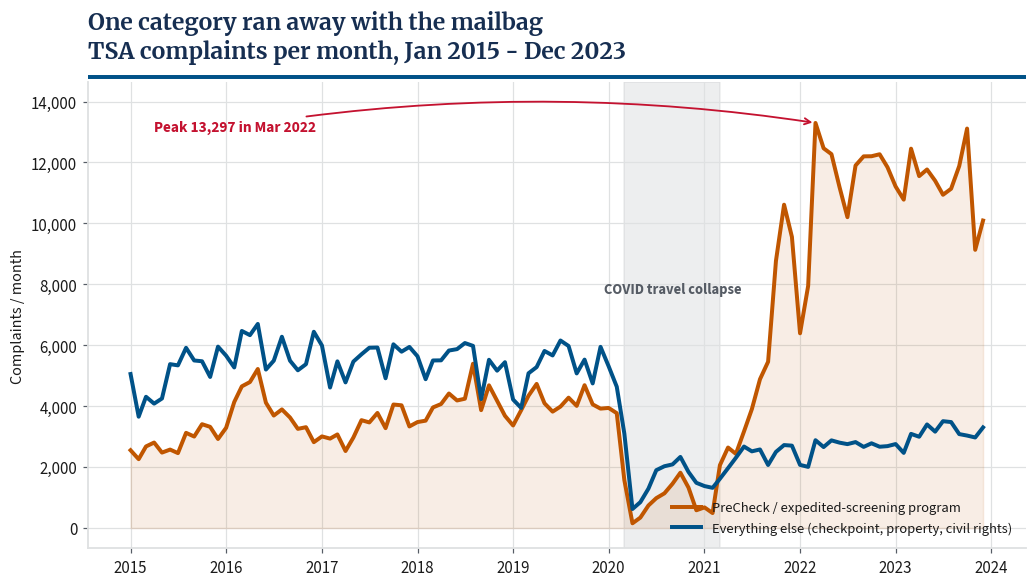

In [7]:
# --- Program vs. checkpoint line plot -------------------------------------

# Split every complaint into the PreCheck program vs. everything else
m = (cat_c.assign(grp=np.where(cat_c.clean_cat == PRE, "prog", "cp"))
     .pivot_table(index="month", columns="grp", values="count", aggfunc="sum").fillna(0))

# Create the figure and axis
fig, ax = plt.subplots()
ax.plot(m.index, m["prog"], color=ORANGE, lw=2.6, label="PreCheck / expedited-screening program")
ax.plot(m.index, m["cp"], color=TSA_BLUE, lw=2.6, label="Everything else (checkpoint, property, civil rights)")
ax.fill_between(m.index, m["prog"], color=ORANGE, alpha=0.10)
ax.yaxis.set_major_formatter(thousands)
tsa_title(ax, "One category ran away with the mailbag\nTSA complaints per month, Jan 2015 - Dec 2023")
ax.set_ylabel("Complaints / month")
ax.legend(loc="lower right")

# Shade the COVID collapse and call out the peak
ax.axvspan(pd.Timestamp("2020-03-01"), pd.Timestamp("2021-03-01"), color=BASE, alpha=0.10, zorder=0)
ax.annotate("COVID travel collapse", xy=(pd.Timestamp("2020-09-01"), m.values.max() * 0.58),
            ha="center", color=BASE, fontsize=9.5, fontweight="bold")
pk = m["prog"].idxmax()
ax.annotate(f"Peak {m['prog'].max():,.0f} in {pk:%b %Y}", xy=(pk, m["prog"].max()),
            xytext=(pd.Timestamp("2015-04-01"), m["prog"].max() * 0.99),
            color=TSA_RED, fontsize=10, fontweight="bold", va="center",
            arrowprops=dict(arrowstyle="->", color=TSA_RED, lw=1.2,
                            connectionstyle="arc3,rad=-0.08"))
ax.set_ylim(top=m.values.max() * 1.10)
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
fig.savefig(FIGS + "01_line_program_vs_checkpoint.png"); plt.show()


## Visual 2 | Stacked bar: the mix flipped
Read as share rather than volume, the same nine years show a category that was a third of the mailbag in 2015 becoming three quarters of it by 2023, squeezing every operational category into a sliver.

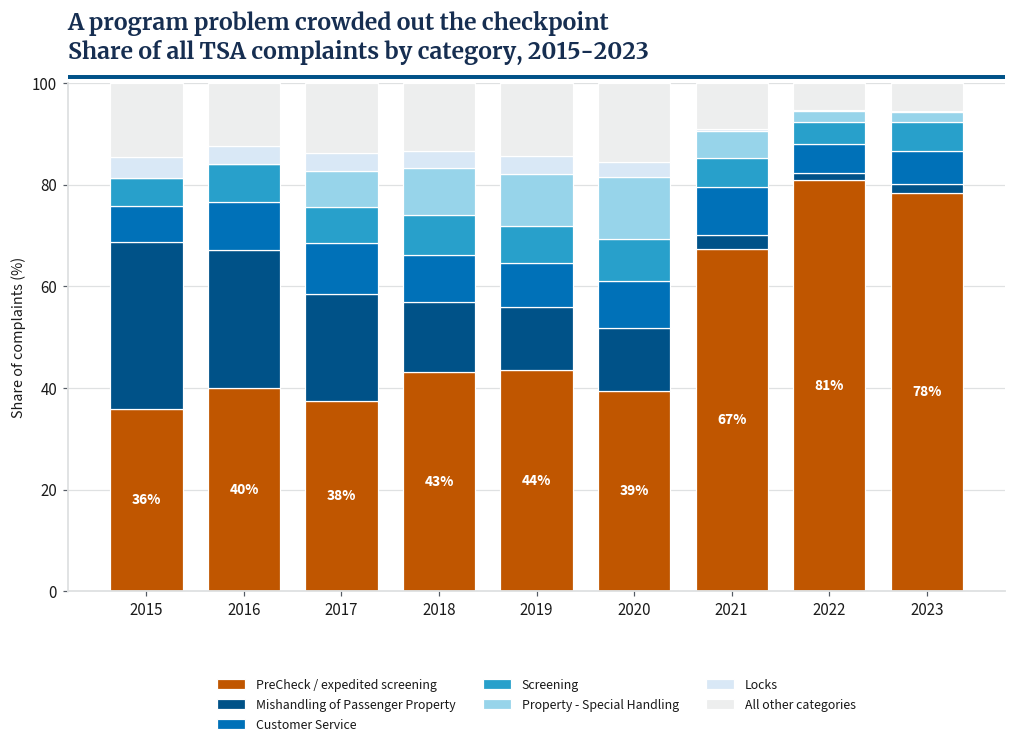

In [8]:
# --- 100% stacked bar of category mix by year -----------------------------

# Keep the six largest categories, roll everything else into one band
top6 = cat_c.groupby("clean_cat")["count"].sum().nlargest(6).index.tolist()
order = [PRE] + [c for c in top6 if c != PRE] + ["All other categories"]
yp = (cat_c.assign(g=np.where(cat_c.clean_cat.isin(top6), cat_c.clean_cat, "All other categories"))
      .pivot_table(index="yr", columns="g", values="count", aggfunc="sum").fillna(0))[order]
share = yp.div(yp.sum(axis=1), axis=0) * 100

# Create the figure and axis. The six checkpoint bands step down the theme's own
# blue tints, so the orange band is the only thing that reads as a second story.
fig, ax = plt.subplots(figsize=(11, 6))
cols = [ORANGE, TSA_BLUE, BLUE_MD, BLUE_LT, BLUE_PALE, BLUE_MIST, SHADE]
bot = np.zeros(len(share))
for c, col in zip(order, cols):
    ax.bar(share.index.astype(str), share[c], bottom=bot, color=col, width=0.74,
           label=("PreCheck / expedited screening" if c == PRE else c),
           edgecolor="white", linewidth=0.8)
    bot += share[c].values
for i, y in enumerate(share.index):
    ax.text(i, share.loc[y, PRE] / 2, f"{share.loc[y, PRE]:.0f}%", ha="center", va="center",
            color="white", fontweight="bold", fontsize=10)
ax.set_ylim(0, 100); ax.set_ylabel("Share of complaints (%)")
tsa_title(ax, "A program problem crowded out the checkpoint\n"
              "Share of all TSA complaints by category, 2015-2023")
ax.legend(loc="lower center", bbox_to_anchor=(0.5, -0.30), ncol=3, fontsize=9)
ax.grid(axis="x", visible=False)
fig.savefig(FIGS + "02_stacked_bar_category_mix.png"); plt.show()


## Visual 3 | Bar chart: why the flood is unmanageable
Drilling into 2023 subcategories exposes the operational problem behind slide 2: the biggest bucket in the entire agency is an **unlabeled** expedited-screening code. A log axis is used because that bucket is more than twelve times the next largest, and a linear axis would render every checkpoint issue invisible.

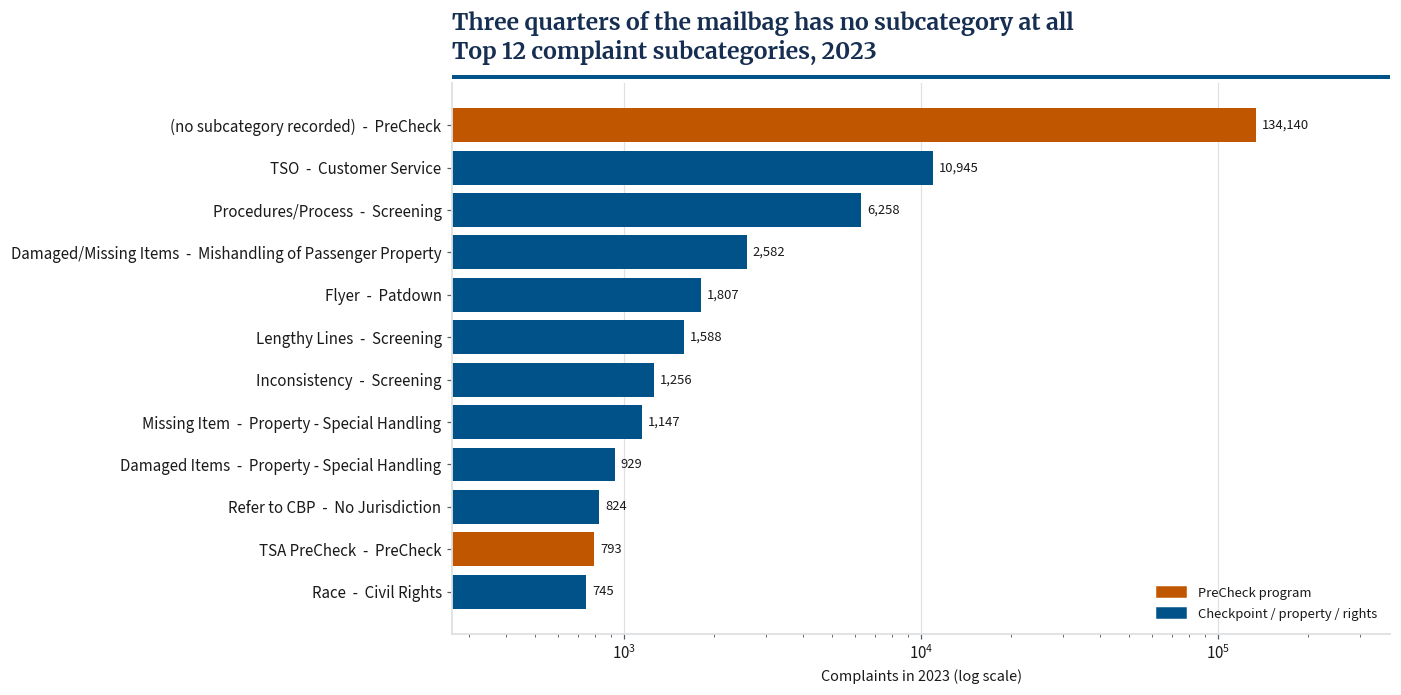

In [9]:
# --- Top 2023 subcategories, horizontal bar -------------------------------

# Rank subcategories for the last complete year; "*" marks a cleaned label
s23 = (sub_c[sub_c.yr == 2023].groupby(["clean_cat", "clean_subcat"])["count"].sum()
       .nlargest(12).reset_index())
s23["lab"] = (s23.clean_subcat.str.lstrip("*").replace("", "(no subcategory recorded)")
              + "  -  " + s23.clean_cat.str.replace(PRE, "PreCheck", regex=False))
s23 = s23.iloc[::-1]

# Create the figure and axis
fig, ax = plt.subplots(figsize=(11, 6.5))
b = ax.barh(s23.lab, s23["count"], color=[ORANGE if c == PRE else TSA_BLUE for c in s23.clean_cat])
ax.bar_label(b, fmt="{:,.0f}".format, padding=4, fontsize=9.5, color=INK)
ax.set_xscale("log"); ax.set_xlabel("Complaints in 2023 (log scale)")
tsa_title(ax, "Three quarters of the mailbag has no subcategory at all\n"
              "Top 12 complaint subcategories, 2023")
ax.legend(handles=[Patch(color=ORANGE, label="PreCheck program"),
                   Patch(color=TSA_BLUE, label="Checkpoint / property / rights")],
          loc="lower right")
ax.grid(axis="y", visible=False); ax.margins(x=0.20)
fig.savefig(FIGS + "03_barh_subcategories_2023.png"); plt.show()


## Visual 4 | Heat map: the floor under the flood
With PreCheck set aside, every complaint an airport *can* control is normalized to complaints per million CY2023 boardings. Rows are the 25 busiest airports, sorted worst to best. The heat is not uniform - it clusters by airport and by category, which is what makes it actionable.

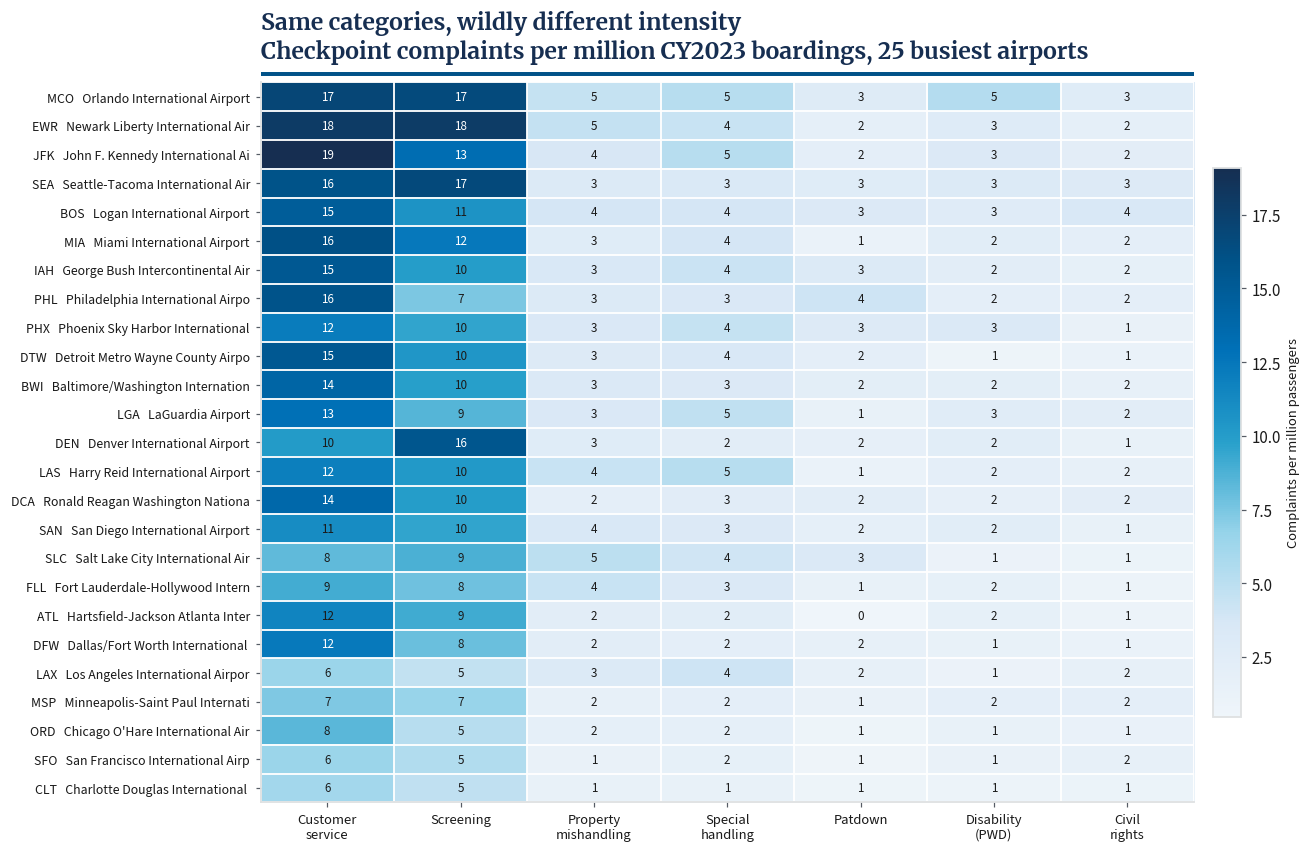

In [10]:
# --- Heat map: airport x category complaint rate --------------------------

# Eight operational categories, rate-normalized, 25 busiest airports, worst first
hm_cats = ["Customer Service", "Screening", "Mishandling of Passenger Property",
           "Property - Special Handling", "Patdown", "Persons w/ Disabilities (PWD)",
           "Civil Rights"]
h = peers.nlargest(25, "enp23")
H = h[hm_cats].div(h.enp23 / 1e6, axis=0).loc[h.sort_values("cp_rate", ascending=False).index]

# Create the figure and axis. TSA_SEQ keeps the surface inside the agency blues
# rather than borrowing an off-brand heat ramp.
fig, ax = plt.subplots(figsize=(11.5, 8.5))
im = ax.imshow(H.values, cmap=TSA_SEQ, aspect="auto")
short = {"Mishandling of Passenger Property": "Property\nmishandling",
         "Property - Special Handling": "Special\nhandling",
         "Persons w/ Disabilities (PWD)": "Disability\n(PWD)",
         "Customer Service": "Customer\nservice", "Civil Rights": "Civil\nrights"}
ax.set_xticks(range(len(hm_cats)))
ax.set_xticklabels([short.get(c, c) for c in hm_cats], fontsize=9.5)
ax.set_yticks(range(len(H)))
ax.set_yticklabels([f"{i}   {h.loc[i, 'airport_name'][:32]}" for i in H.index], fontsize=9)
ax.set_xticks(np.arange(-0.5, H.shape[1]), minor=True)
ax.set_yticks(np.arange(-0.5, H.shape[0]), minor=True)
ax.grid(which="minor", color="white", lw=1.2)
ax.tick_params(which="minor", length=0)
for i in range(H.shape[0]):
    for j in range(H.shape[1]):
        v = H.values[i, j]
        ax.text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=8.5,
                color=ramp_text(v, H.values.max()))
tsa_title(ax, "Same categories, wildly different intensity\n"
              "Checkpoint complaints per million CY2023 boardings, 25 busiest airports")
cb = fig.colorbar(im, ax=ax, fraction=0.028, pad=0.02)
cb.set_label("Complaints per million passengers", fontsize=9.5)
cb.outline.set_edgecolor(RULE)
ax.grid(False, which="major")
fig.savefig(FIGS + "04_heatmap_airport_category.png"); plt.show()


## Visual 5 | Box plot: size is not the excuse
If big airports simply attracted more complaints, the boxes would step upward by hub class. They do not - the medians nearly coincide while the **spread inside each class is enormous**. Every dot is one airport, so the audience can see the distribution and the outliers at the same time.

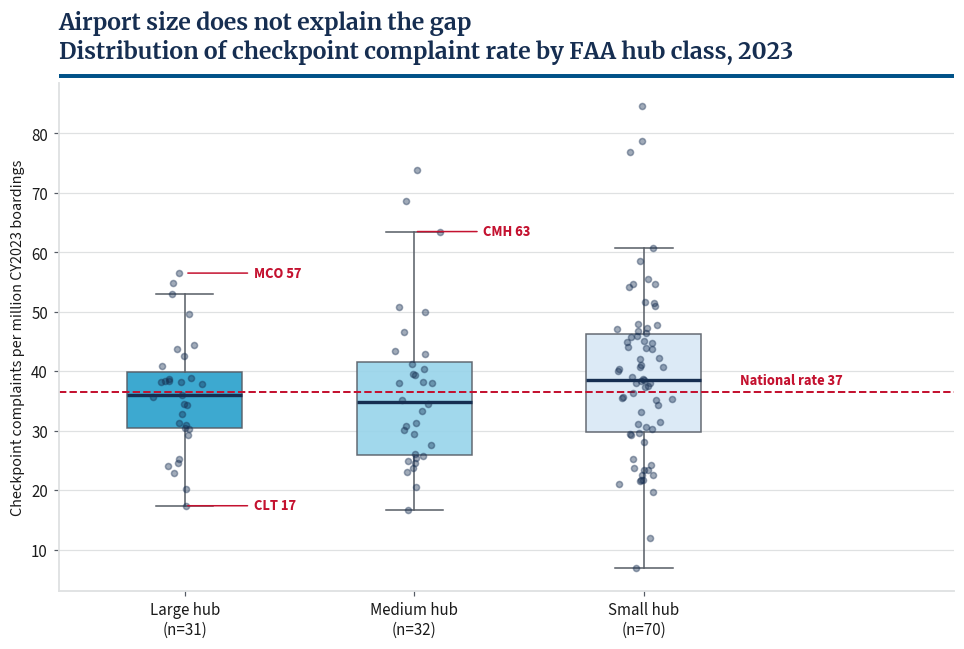

In [11]:
# --- Box plot of checkpoint rate by FAA hub class -------------------------

# Compare distributions across hub classes, floored at 500K boardings so a single
# complaint at a tiny field cannot masquerade as a huge rate
hub_lab = {"L": "Large hub", "M": "Medium hub", "S": "Small hub"}
bx = rates[rates.hub.isin(hub_lab) & (rates.enp23 >= 5e5)].assign(
    hub_lab=lambda d: d.hub.map(hub_lab))
groups = ["Large hub", "Medium hub", "Small hub"]
data = [bx.loc[bx.hub_lab == g, "cp_rate"].values for g in groups]

# Create the figure and axis
fig, ax = plt.subplots(figsize=(10.5, 6))
bp = ax.boxplot(data, tick_labels=[f"{g}\n(n={len(d)})" for g, d in zip(groups, data)],
                patch_artist=True, widths=0.5, showfliers=False,
                medianprops=dict(color=BLUE_DK, lw=2.2),
                whiskerprops=dict(color=BASE), capprops=dict(color=BASE))
for patch, col in zip(bp["boxes"], [BLUE_LT, BLUE_PALE, BLUE_MIST]):
    patch.set_facecolor(col); patch.set_edgecolor(BASE); patch.set_alpha(0.90)

# Overlay every airport so the reader sees the raw distribution, not just the box
rng = np.random.default_rng(7)
for i, g in enumerate(groups, start=1):
    v = bx.loc[bx.hub_lab == g, "cp_rate"].values
    ax.scatter(rng.normal(i, 0.055, len(v)), v, s=16, color=BLUE_DK, alpha=0.40, zorder=3)
ax.axhline(NAT_CP, color=TSA_RED, ls="--", lw=1.3)
ax.set_xlim(0.45, 4.35)
ax.annotate(f"National rate {NAT_CP:.0f}", xy=(3.42, NAT_CP + 0.7), color=TSA_RED,
            fontsize=9.5, fontweight="bold", va="bottom", ha="left")

# Name only the three airports the narrative uses, so the labels never collide
for code, side in [("CMH", 1), ("MCO", 1), ("CLT", 1)]:
    r = bx.loc[code]
    ax.annotate(f"{code} {r.cp_rate:.0f}",
                xy=(groups.index(r.hub_lab) + 1, r.cp_rate),
                xytext=(groups.index(r.hub_lab) + 1 + 0.30 * side, r.cp_rate),
                fontsize=9.5, fontweight="bold", color=TSA_RED, va="center",
                arrowprops=dict(arrowstyle="-", color=TSA_RED, lw=1.0))
ax.set_ylabel("Checkpoint complaints per million CY2023 boardings")
tsa_title(ax, "Airport size does not explain the gap\n"
              "Distribution of checkpoint complaint rate by FAA hub class, 2023")
ax.grid(axis="x", visible=False)
fig.savefig(FIGS + "05_boxplot_rate_by_hub.png"); plt.show()


## Visual 6 | Choropleth: the problem has a map
Rolling airports up to their state and re-normalizing by that state's boardings turns the spread into geography. States with fewer than one million CY2023 boardings are greyed out rather than colored, because a handful of complaints over a tiny denominator would produce a bright, meaningless red.

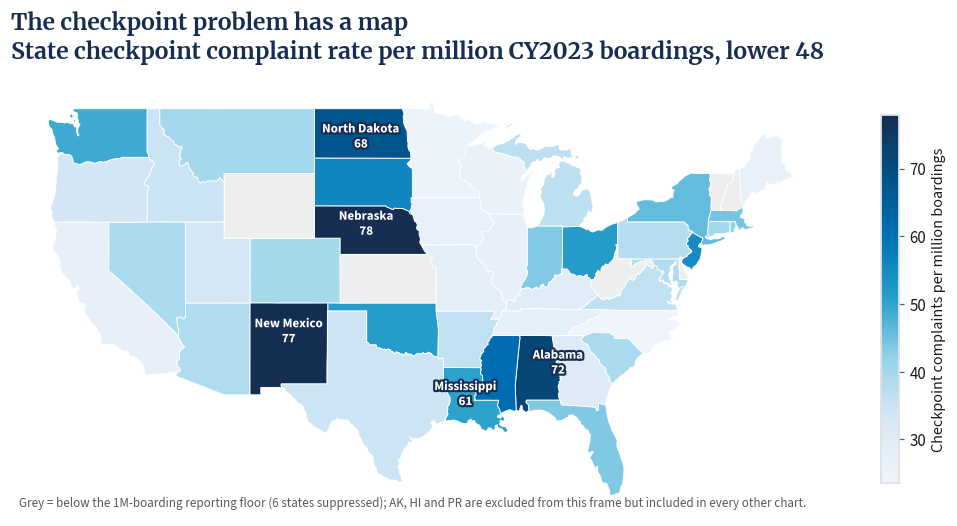

In [12]:
# --- Choropleth of state checkpoint complaint rate ------------------------

# Aggregate to state, then re-normalize by that state's total boardings
st = rates.dropna(subset=["state"]).groupby("state")[["checkpoint", "enp23"]].sum()
st["cp_rate"] = st.checkpoint / (st.enp23 / 1e6)
st.loc[st.enp23 < 1e6, "cp_rate"] = np.nan          # suppressed: denominator too small
suppressed = int((st.enp23 < 1e6).sum())

gdf = gpd.read_file(DATA + "us-states.geojson").merge(
    st.reset_index(), left_on="name", right_on="state", how="left")
lower48 = gdf[~gdf.name.isin(["Alaska", "Hawaii", "Puerto Rico"])]

# Create the figure and axis; same TSA_SEQ ramp as the heat map, same meaning
fig, ax = plt.subplots(figsize=(12, 7))
lower48.plot(column="cp_rate", cmap=TSA_SEQ, linewidth=0.6, edgecolor="white", ax=ax,
             legend=True,
             missing_kwds={"color": SHADE, "edgecolor": "white"},
             legend_kwds={"label": "Checkpoint complaints per million boardings",
                          "shrink": 0.62})
# Label the five hottest states; nudge the two that share a border. Those five
# sit at the dark end of the ramp, so the label is white inside a navy halo.
NUDGE = {"Mississippi": (-2.6, -1.2), "Alabama": (1.6, 0.6), "Nebraska": (0, 0.4)}
halo = [pe.withStroke(linewidth=2.8, foreground=BLUE_DK)]
for _, r in lower48.nlargest(5, "cp_rate").iterrows():
    c = r.geometry.representative_point()
    dx, dy = NUDGE.get(r["name"], (0, 0))
    ax.annotate(f"{r['name']}\n{r.cp_rate:.0f}", xy=(c.x + dx, c.y + dy), ha="center",
                va="center", fontsize=8.5, fontweight="bold", color="white",
                path_effects=halo)
ax.set_axis_off()
tsa_title(ax, "The checkpoint problem has a map\n"
              "State checkpoint complaint rate per million CY2023 boardings, lower 48",
          rule=False)
ax.annotate(f"Grey = below the 1M-boarding reporting floor ({suppressed} states suppressed); "
            "AK, HI and PR are excluded from this frame but included in every other chart.",
            xy=(0.01, 0.02), xycoords="axes fraction", fontsize=8.5, color=BASE)
fig.savefig(FIGS + "06_choropleth_state_rate.png"); plt.show()


## Visual 7 | Custom visual: the ask, drawn to scale
A custom gap-to-median plot. Each row is one of the ten highest-rate peer hubs; the navy dot is the peer median, the red dot is where that airport sits today, and the red bar between them is the ask. The label converts each gap back into the only unit leadership cares about - complaints per year that would stop being filed.

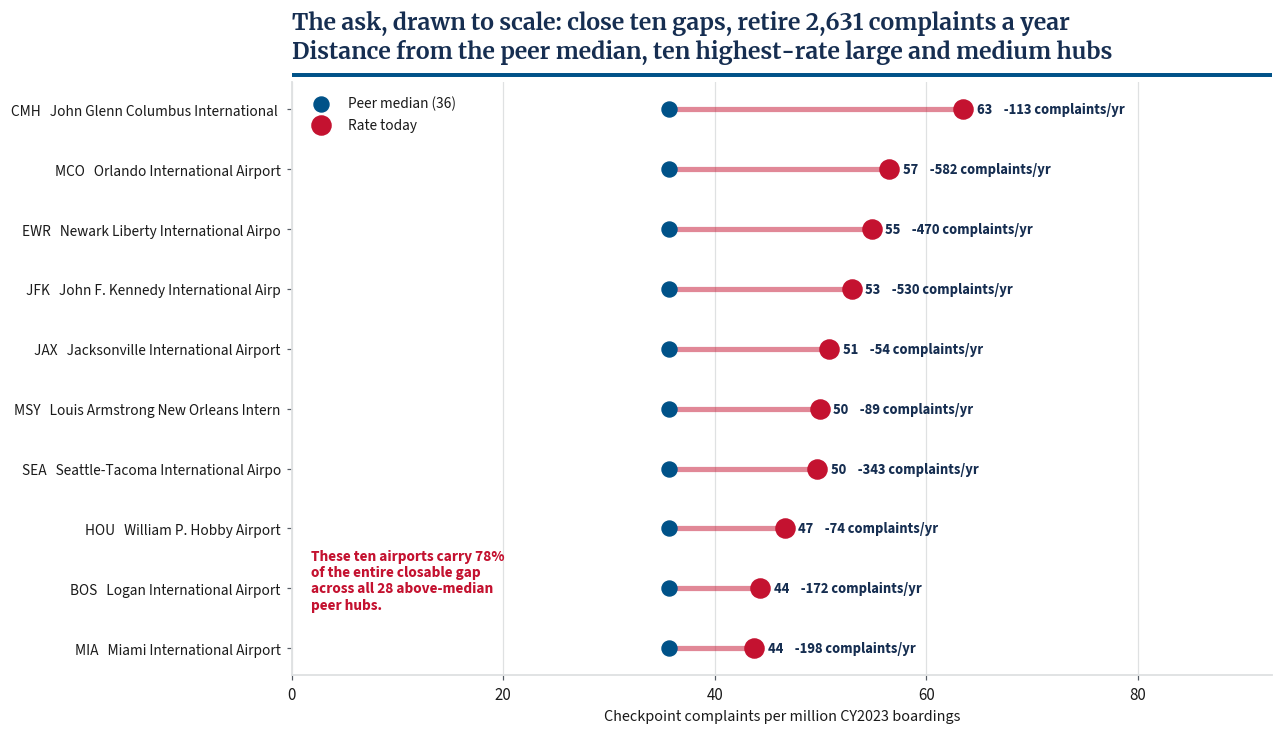

In [13]:
# --- Custom visual: distance from the peer median -------------------------

# Rank the ten worst peers and convert each rate gap back into annual complaints
w = worst10.sort_values("cp_rate")
tot_excess, top_share = int(w.excess.sum()), w.excess.sum() / peers.excess.sum()

# Create the figure and axis
fig, ax = plt.subplots(figsize=(11.5, 7))
y = np.arange(len(w))
ax.hlines(y, MED, w.cp_rate, color=TSA_RED, lw=3.4, alpha=0.50, zorder=1)
ax.scatter([MED] * len(w), y, s=95, color=TSA_BLUE, zorder=3, label=f"Peer median ({MED:.0f})")
ax.scatter(w.cp_rate, y, s=155, color=TSA_RED, zorder=3, label="Rate today")
for i, (code, r) in enumerate(w.iterrows()):
    ax.text(r.cp_rate + 1.3, i, f"{r.cp_rate:.0f}    -{int(r.excess):,} complaints/yr",
            va="center", fontsize=9.5, fontweight="bold", color=BLUE_DK)
ax.set_yticks(y)
ax.set_yticklabels([f"{i}   {n[:34]}" for i, n in zip(w.index, w.airport_name)], fontsize=10)
ax.set_xlim(0, w.cp_rate.max() * 1.46)
ax.set_xlabel("Checkpoint complaints per million CY2023 boardings")
tsa_title(ax, f"The ask, drawn to scale: close ten gaps, retire {tot_excess:,} complaints a year\n"
              f"Distance from the peer median, ten highest-rate large and medium hubs")
# Legend and call-out both live in the empty band left of the median dot
ax.legend(loc="upper left", fontsize=10)
ax.grid(axis="y", visible=False)
ax.annotate(f"These ten airports carry {top_share:.0%}\nof the entire closable gap\n"
            f"across all {int((peers.cp_rate > MED).sum())} above-median\npeer hubs.",
            xy=(0.02, 0.16), xycoords="axes fraction", ha="left", va="center",
            fontsize=10, color=TSA_RED, fontweight="bold")
fig.savefig(FIGS + "07_custom_gap_to_median.png"); plt.show()


---
## Building the medium: the executive briefing deck
The seven figures above are the slide bodies. The cell below assembles them into `deck/tsa_checkpoint_briefing.html` - one self-contained file (images base64-embedded, no external assets), navigable on screen and printable straight to PDF. Each slide carries a takeaway headline rather than a chart title, and the deck closes on the ask.

In [14]:
# --- Assemble the self-contained HTML briefing deck -----------------------
# The deck is dressed as a TSA.gov page rather than a generic slide template:
# the agency-blue header band, the Merriweather / Source Sans Pro pairing, red
# section headings, flat square cards ruled in 2px #dfe1e2, and the USWDS alert
# pattern for the one number that carries the ask.

def embed(path, mime="image/png"):
    with open(path, "rb") as fh:
        return f"data:{mime};base64," + base64.b64encode(fh.read()).decode()

# Both webfonts ride inside the file, so the deck keeps the client's typography
# on a machine with no network and neither face installed.
FONT_SERIF = embed("fonts/Merriweather-400.woff2", "font/woff2")
FONT_SANS  = embed("fonts/SourceSans3-400.woff2", "font/woff2")

SLIDES = [
    ("01_line_program_vs_checkpoint.png", "1 / The flood is one category",
     "Complaints more than doubled from 2021 to 2023 and sit 53% above 2019. Almost "
     "all of that growth is expedited-screening program traffic. The checkpoint line "
     "is nearly flat across nine years."),
    ("02_stacked_bar_category_mix.png", "2 / The mix flipped under us",
     "PreCheck went from a third of the mailbag to three quarters. Every operational "
     "category we actually staff for has been squeezed into a sliver of the reporting."),
    ("03_barh_subcategories_2023.png", "3 / And we cannot manage it",
     "The single largest bucket in the agency carries no subcategory at all. "
     "134,140 complaints in 2023 are, for management purposes, blank."),
    ("04_heatmap_airport_category.png", "4 / Underneath sits the real signal",
     "Set PreCheck aside and normalize to boardings. The heat clusters by airport and "
     "by category - screening, customer service and property, not random noise."),
    ("05_boxplot_rate_by_hub.png", "5 / Size is not the excuse",
     "Medians barely move across hub class while the spread inside each class is huge. "
     "Volume does not explain who gets complained about."),
    ("06_choropleth_state_rate.png", "6 / The gap has a geography",
     "Rolled up to states and re-normalized, the checkpoint rate varies more than "
     "threefold across the country - a management map, not a passenger map."),
    ("07_custom_gap_to_median.png", "7 / The ask, drawn to scale",
     "Ten airports carry most of the closable gap. Bringing them to the peer median "
     "is a concrete, budgetable, measurable target."),
]

# Every slide wears the same band and the same footer, so authorship travels with
# the document even though it is styled in the client's system.
BAND = ('<header class="band"><span class="agency">Transportation Security '
        'Administration</span><span class="crumb">{}</span></header>')
FOOT = ('<footer class="foot"><span>The Flood and the Floor &middot; complaint review, '
        'CY2015-2023</span><span>David Jorgensen &middot; DSC640</span></footer>')

cards = "".join(f"""
  <section class="slide">
    {BAND.format("Complaint Review &middot; CY2015-2023")}
    <div class="pad">
      <h2>{t}</h2>
      <p class="take">{s}</p>
      <img src="{embed(FIGS + f)}" alt="{t}">
    </div>
    {FOOT}
  </section>""" for f, t, s in SLIDES)

ask = f"""
  <section class="slide ask">
    {BAND.format("Complaint Review &middot; The decision")}
    <div class="pad">
      <h2>8 / What we are asking you to approve</h2>
      <ol>
        <li><b>Re-code the expedited-screening intake taxonomy and fund self-service
        PreCheck application-status lookup.</b> {share.loc[2023, PRE]:.0f}% of 2023 complaints
        are PreCheck-program traffic and {sub_c[(sub_c.yr==2023) & (sub_c.clean_cat==PRE)
        & (sub_c.clean_subcat=='*')]['count'].sum():,.0f} of them arrive with no subcategory.
        We cannot triage, trend, or staff against a blank label.</li>
        <li><b>Fund a 90-day "Checkpoint Ten" intervention</b> at
        {', '.join(worst10.sort_values('cp_rate', ascending=False).index)} - the ten
        highest-rate large and medium hubs. Target: peer median
        ({MED:.0f} per million) by 31 Dec 2027.</li>
      </ol>
      <p class="metric"><b>{tot_excess:,}</b> complaints a year retired by item 2 alone
      &mdash; {top_share:.0%} of the closable gap across all
      {int((peers.cp_rate > MED).sum())} above-median peer hubs.</p>
      <p class="take">Measure of success: quarterly checkpoint complaints per million
      boardings, reported by hub, with the peer median as the standing benchmark.</p>
    </div>
    {FOOT}
  </section>
  <section class="slide notes">
    {BAND.format("Complaint Review &middot; Notes on the data")}
    <div class="pad">
      <h2>9 / What is in these numbers, and what is not</h2>
      <ul>
        <li>Source: Data Liberation Project FOIA release of TSA complaint counts
        (seven PDF reports, Jan 2015 - Jan 2024), joined to FAA CY2023 commercial-service
        boardings and the public IATA/ICAO airport lookup.</li>
        <li><b>{una['count'].sum() / cat['count'].sum():.0%} of complaints carry no airport code</b>
        and are excluded from every airport, state and rate chart; they are included in the
        national trend charts. They are {una.loc[una.clean_cat == PRE, 'count'].sum()
        / una['count'].sum():.0%} PreCheck.</li>
        <li>Rates use CY2023 boardings against CY2023 complaints. 2024 is excluded entirely
        (the data stops in January).</li>
        <li>States below 1M boardings are suppressed, not colored. Peer comparisons are
        limited to airports above 3M boardings.</li>
        <li>These are <b>complaint counts, not substantiated findings</b>. A high rate is a
        signal to investigate, never evidence of misconduct by any named officer.</li>
      </ul>
    </div>
    {FOOT}
  </section>"""


# The Summary Paper (assignment write-up) rides along in the same file, appended
# after the notes slide as a plain document - not a "10th slide" - so the deck
# stays a single self-contained artifact without polluting the presentation flow.
SUMMARY_PAPER = """
  <article class="paper">
    <p class="kicker">Appendix &middot; not part of the briefing &middot; DSC640 summary paper</p>
    <h1>Summary Paper</h1>
    <p><strong>Audience.</strong> TSA senior leadership: the Executive Assistant Administrators for Security Operations and for Enrollment Services &amp; Vetting Programs, plus the Contact Center chief. Internal, executive, fluent in this data, so nothing is defined and every chart leads with a conclusion.</p>
    <p><strong>Purpose / call to action.</strong> A decision, not a recap. Approve two FY2027 actions: re-code the expedited-screening intake taxonomy and add self-service PreCheck status lookup, because 78% of 2023 complaints are PreCheck traffic whose largest bucket has no subcategory at all; and fund a 90-day "Checkpoint Ten" intervention at the ten highest-rate hubs, targeting the peer median by 31 December 2027, retiring ~2,600 complaints a year and 78% of the closable gap. A third ask makes it durable: adopt checkpoint complaints per million boardings as a quarterly metric.</p>
    <p><strong>Medium.</strong> A nine-slide executive briefing deck in one self-contained HTML file that prints to PDF, sized for a 15-minute slot where the narrative is spoken and the last slide carries the ask.</p>
    <p><strong>Design.</strong> The briefing is drawn in the client's own system rather than a house style: every color, both typefaces and the flat, square, hairline-ruled structure are taken from TSA.gov (the <code>tsa_uswds</code> theme built on the U.S. Web Design System) - agency blue <code>#005288</code> for the header band, links and primary marks, agency red <code>#c41230</code> for section headings and the ask, USWDS accent-warm <code>#c05600</code> and base greys for everything else, Merriweather headings over Source Sans Pro body copy, USWDS alert and hero-callout patterns for the two blocks that carry a number. One encoding runs through all seven figures: orange = the PreCheck program problem, TSA blue = the checkpoint problem leadership can manage, red = the ask, grey = context or suppressed data. <em>Similarity</em> carries that meaning slide to slide; <em>proximity</em> pairs each takeaway above its chart; <em>figure/ground</em> keeps every plot on white under a single sequential ramp interpolated through the theme's own blue tints, so saturation means one thing and never introduces a second hue; <em>continuity</em> comes from left-aligned two-line serif titles seated on the same agency-blue rule the site puts under a section heading, and a shared year axis; <em>closure</em> drops top and right spines; <em>enclosure</em> annotates, via the COVID band, the boxes, and each slide's 2px card rule. <strong>Color</strong> is four hues, colorblind-safe in the orange/blue pairing, never decorative and never off-brand. <strong>Text</strong> is the client's two faces - serif for headings, sans for everything else - nothing below 8.5pt. <strong>Alignment</strong> is left, labels flush to their marks. <strong>Sizing</strong> encodes magnitude only. <strong>Spacing</strong> is gridded so each figure reads as one object.</p>
    <p><strong>Ethical considerations.</strong> The seven source PDFs partition time cleanly, with zero duplicate or conflicting airport-month pairs, so no de-duplication rule was invented; 2024 is dropped, as the data ends in January. Raw counts became complaints per million CY2023 boardings; ranking ATL against CMH on volume would be indefensible. <strong>43% of complaints carry no airport code</strong>: excluded from every airport, state and rate chart, kept in the national trends, and disclosed on the deck rather than buried, because that bucket is 81% PreCheck - the finding itself. Peer comparisons are floored at 3M boardings and state coloring at 1M, both labeled, as is visual 3's log axis. Boardings ignore connecting passengers screened elsewhere, understating hubs like CLT, so the ask investigates gaps rather than punishing them. Sources are public, citable and PII-free: a Data Liberation Project FOIA release of TSA's reporting, FAA's enplanement file, and the open IATA/ICAO lookup. Reconciling the last two surfaced seven state errors, including Omaha filed under Iowa; FAA was treated as authoritative and the discrepancies printed, not overwritten. The main risk is a ranking reading as an accusation; since these are allegations, not findings, nothing is disaggregated below the airport, no officer is named, and the deck states a high rate is only a signal to investigate.</p>
  </article>"""

html = f"""<!doctype html>
<html lang="en"><head><meta charset="utf-8">
<meta name="viewport" content="width=device-width, initial-scale=1">
<title>The Flood and the Floor - TSA Complaint Review</title>
<style>
  @font-face {{ font-family:"Merriweather"; src:url({FONT_SERIF}) format("woff2");
                font-weight:400 700; font-style:normal; font-display:swap; }}
  @font-face {{ font-family:"Source Sans 3"; src:url({FONT_SANS}) format("woff2");
                font-weight:400 700; font-style:normal; font-display:swap; }}

  /* TSA.gov design tokens, same values the figures are drawn in */
  :root {{ --blue:{TSA_BLUE}; --blue-dk:{BLUE_DK}; --blue-mist:{BLUE_MIST};
           --red:{TSA_RED}; --orange:{ORANGE}; --orange-lt:{ORANGE_LT};
           --ink:{INK}; --base:{BASE}; --rule:{RULE}; --shade:{SHADE};
           --serif:"Merriweather",Georgia,Cambria,"Times New Roman",Times,serif;
           --sans:"Source Sans 3","Source Sans Pro","Helvetica Neue",Helvetica,Roboto,Arial,sans-serif; }}
  * {{ box-sizing:border-box; }}
  body {{ margin:0; background:var(--shade); color:var(--ink);
          font-family:var(--sans); font-size:16px; line-height:1.52; }}

  /* Flat, square, 2px-ruled card - the USWDS card, not a slide template */
  .slide {{ background:#fff; width:min(1120px,94vw); margin:26px auto;
            border:2px solid var(--rule); border-radius:0;
            display:flex; flex-direction:column; page-break-after:always; }}
  .pad {{ padding:30px 46px 38px; flex:1; }}

  /* Agency band: the tsa.gov extended nav bar, reduced to a slide header */
  .band {{ background:var(--blue); color:#fff; padding:9px 46px;
           display:flex; justify-content:space-between; align-items:baseline;
           gap:16px; flex-wrap:wrap; }}
  .slide.ask .band {{ background:var(--red); }}
  .slide.notes .band {{ background:var(--base); }}
  .agency {{ font-weight:700; font-size:13px; letter-spacing:.04em;
             text-transform:uppercase; }}
  .crumb {{ font-size:12px; letter-spacing:.10em; text-transform:uppercase;
            color:var(--blue-mist); }}
  .slide.ask .crumb, .slide.notes .crumb {{ color:#fff; opacity:.85; }}

  /* tsa.gov type hierarchy: serif headings, H1 agency blue, H2 agency red */
  h1, h2 {{ font-family:var(--serif); font-weight:700; }}
  h1 {{ font-size:40px; line-height:1.18; margin:0 0 10px; color:#fff; }}
  h2 {{ font-size:25px; line-height:1.28; margin:0 0 14px; color:var(--red); }}

  /* The hero callout block, straight off the tsa.gov front page */
  .hero {{ background:var(--blue); padding:30px 34px; margin:0 0 26px; max-width:44rem; }}
  .sub {{ font-size:18px; color:var(--blue-mist); font-weight:600; margin:0; }}

  .take {{ font-size:15.5px; line-height:1.58; color:#3d4551; max-width:78ch;
           margin:0 0 22px; }}
  img {{ width:100%; height:auto; display:block; border:1px solid var(--rule); }}
  ol, ul {{ font-size:16px; line-height:1.6; max-width:82ch; padding-left:22px; margin:0; }}
  li {{ margin-bottom:14px; }}

  /* USWDS alert: flat tint, 8px status bar, square corners */
  .metric {{ font-size:17px; background:var(--orange-lt);
             border-left:8px solid var(--red); padding:16px 20px; margin:24px 0; }}
  .metric b {{ font-family:var(--serif); font-size:26px; color:var(--red);
                margin-right:.18em; }}
  .meta {{ font-size:13.5px; color:var(--base); line-height:1.7; margin:0; }}

  .foot {{ border-top:1px solid var(--rule); padding:10px 46px; font-size:12px;
           color:var(--base); display:flex; justify-content:space-between;
           gap:16px; flex-wrap:wrap; }}

  @media print {{ body {{ background:#fff; }}
    .slide {{ margin:0; width:100%; border:none; }} }}

  /* Summary paper: appended reference doc, not part of the slide flow */
  .paper {{ background:#fff; width:min(880px,94vw); margin:40px auto 60px;
            border:2px solid var(--rule); border-radius:0; padding:44px 54px 54px;
            page-break-before:always; }}
  .paper .kicker {{ font-size:12px; letter-spacing:.10em; text-transform:uppercase;
                     color:var(--base); border-bottom:1px solid var(--rule);
                     padding-bottom:12px; margin:0 0 22px; }}
  .paper h1 {{ font-family:var(--serif); font-weight:700; font-size:28px;
               line-height:1.24; color:var(--blue); margin:0 0 24px; }}
  .paper p {{ font-size:15.5px; line-height:1.68; color:#3d4551; max-width:76ch;
              margin:0 0 18px; }}
  .paper p strong {{ color:var(--ink); }}
  .paper p code {{ font-family:ui-monospace,Menlo,Consolas,monospace; font-size:.92em;
                    background:var(--shade); padding:.05em .35em; }}
</style></head><body>
  <section class="slide title">
    {BAND.format("Prepared for the Administrator's senior staff")}
    <div class="pad">
      <div class="hero">
        <h1>The Flood and the Floor</h1>
        <p class="sub">Two complaint problems wearing the same uniform, 2015-2023</p>
      </div>
      <p class="take">Our complaint volume more than doubled between 2021 and 2023, and it was
      not the checkpoint. {share.loc[2023, PRE]:.0f}% of 2023 complaints are expedited-screening
      program traffic that no checkpoint can fix. Underneath that flood sits a stable,
      measurable checkpoint signal that varies
      {peers.cp_rate.max() / peers.cp_rate.min():.1f}x across
      {len(peers)} comparable hubs - and that spread is ours to close.</p>
      <p class="meta">David Jorgensen &middot; DSC640 Weeks 9 &amp; 10 &mdash; a student
      briefing, styled in the TSA.gov design system, not an official TSA publication.<br>
      Sources: Data Liberation Project TSA complaint counts (FOIA); FAA CY2023
      commercial-service boardings; IATA/ICAO airport lookup.</p>
    </div>
    {FOOT}
  </section>{cards}{ask}{SUMMARY_PAPER}
</body></html>"""

with open("deck/tsa_checkpoint_briefing.html", "w") as fh:
    fh.write(html)
print(f"deck written: deck/tsa_checkpoint_briefing.html  ({len(html) / 1e6:.2f} MB, "
       f"cover + {len(SLIDES) + 2} numbered slides, fonts and figures embedded, "
      f"fully self-contained)")


deck written: deck/tsa_checkpoint_briefing.html  (1.65 MB, cover + 9 numbered slides, fonts and figures embedded, fully self-contained)


---
## Summary Paper

**Audience.** TSA senior leadership: the Executive Assistant Administrators for Security Operations and for Enrollment Services & Vetting Programs, plus the Contact Center chief. Internal, executive, fluent in this data, so nothing is defined and every chart leads with a conclusion.

**Purpose / call to action.** A decision, not a recap. Approve two FY2027 actions: re-code the expedited-screening intake taxonomy and add self-service PreCheck status lookup, because 78% of 2023 complaints are PreCheck traffic whose largest bucket has no subcategory at all; and fund a 90-day "Checkpoint Ten" intervention at the ten highest-rate hubs, targeting the peer median by 31 December 2027, retiring ~2,600 complaints a year and 78% of the closable gap. A third ask makes it durable: adopt checkpoint complaints per million boardings as a quarterly metric.

**Medium.** A nine-slide executive briefing deck in one self-contained HTML file that prints to PDF, sized for a 15-minute slot where the narrative is spoken and the last slide carries the ask.

**Design.** The briefing is drawn in the client's own system rather than a house style: every color, both typefaces and the flat, square, hairline-ruled structure are taken from TSA.gov (the `tsa_uswds` theme built on the U.S. Web Design System) - agency blue `#005288` for the header band, links and primary marks, agency red `#c41230` for section headings and the ask, USWDS accent-warm `#c05600` and base greys for everything else, Merriweather headings over Source Sans Pro body copy, USWDS alert and hero-callout patterns for the two blocks that carry a number. One encoding runs through all seven figures: orange = the PreCheck program problem, TSA blue = the checkpoint problem leadership can manage, red = the ask, grey = context or suppressed data. *Similarity* carries that meaning slide to slide; *proximity* pairs each takeaway above its chart; *figure/ground* keeps every plot on white under a single sequential ramp interpolated through the theme's own blue tints, so saturation means one thing and never introduces a second hue; *continuity* comes from left-aligned two-line serif titles seated on the same agency-blue rule the site puts under a section heading, and a shared year axis; *closure* drops top and right spines; *enclosure* annotates, via the COVID band, the boxes, and each slide's 2px card rule. **Color** is four hues, colorblind-safe in the orange/blue pairing, never decorative and never off-brand. **Text** is the client's two faces - serif for headings, sans for everything else - nothing below 8.5pt. **Alignment** is left, labels flush to their marks. **Sizing** encodes magnitude only. **Spacing** is gridded so each figure reads as one object.

**Ethical considerations.** The seven source PDFs partition time cleanly, with zero duplicate or conflicting airport-month pairs, so no de-duplication rule was invented; 2024 is dropped, as the data ends in January. Raw counts became complaints per million CY2023 boardings; ranking ATL against CMH on volume would be indefensible. **43% of complaints carry no airport code**: excluded from every airport, state and rate chart, kept in the national trends, and disclosed on the deck rather than buried, because that bucket is 81% PreCheck - the finding itself. Peer comparisons are floored at 3M boardings and state coloring at 1M, both labeled, as is visual 3's log axis. Boardings ignore connecting passengers screened elsewhere, understating hubs like CLT, so the ask investigates gaps rather than punishing them. Sources are public, citable and PII-free: a Data Liberation Project FOIA release of TSA's reporting, FAA's enplanement file, and the open IATA/ICAO lookup. Reconciling the last two surfaced seven state errors, including Omaha filed under Iowa; FAA was treated as authoritative and the discrepancies printed, not overwritten. The main risk is a ranking reading as an accusation; since these are allegations, not findings, nothing is disaggregated below the airport, no officer is named, and the deck states a high rate is only a signal to investigate.

### The ask, as it appears on the closing slide

1. **Re-code the expedited-screening intake taxonomy and fund self-service PreCheck
   application-status lookup.** Three quarters of the 2023 mailbag is PreCheck-program
   traffic, and its largest bucket arrives with no subcategory at all. We cannot triage,
   trend, or staff against a blank label.
2. **Fund a 90-day "Checkpoint Ten" intervention** at the ten highest-rate large and
   medium hubs, targeting the peer median by 31 December 2027 - roughly **2,600 fewer
   complaints a year**, about **78% of the entire closable gap** across all above-median
   peers.
3. **Adopt checkpoint complaints per million boardings as a standing quarterly metric**,
   reported by hub class against the peer median, so the next review argues about a number
   everyone has already agreed to.